# Heat diffusion (PDE) — the physics-based recipe

Our first **PDE benchmark**, solved with explicit **FTCS** (`pyutils/benchmarks/heat.py`). Same four steps as the vessel.

### Setup — libraries and the heat solver

Put the repository root (`python/`) on the path, import **NumPy** for the field arrays and **Matplotlib** for the plots, apply the shared course plotting style, and load the finite-difference solver `pyutils.benchmarks.heat`. That module supplies `HeatProblem` (geometry, diffusivity, boundary temperatures), the explicit `solve` (the FTCS marcher), and `stable_dt` (the von Neumann step limit) used throughout this notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np
import matplotlib.pyplot as plt
from pyutils import set_plot_style; set_plot_style()
from pyutils.benchmarks import heat

*No output — this cell only prepares the environment.* It leaves the `heat` module and the plotting style loaded; every field below is built with `heat.HeatProblem` and marched with `heat.solve`.

## Step 1 — Derive

A first-law energy balance on a fixed control volume, closed with **Fourier's law** $\boldsymbol{q}=-k\nabla T$ (heat flows down the temperature gradient), gives the **heat (diffusion) equation**

$$\frac{\partial T}{\partial t} = \alpha\nabla^2 T + \frac{\dot q}{\rho c_p},\qquad \alpha=\frac{k}{\rho c_p}.$$

Here $T(\boldsymbol{x},t)$ is temperature, $\alpha$ the **thermal diffusivity** [m$^2$/s], and $\dot q$ a volumetric source. The conservation balance is exact; Fourier's law is the one *modelled* (empirical) closure — the place data could later enter. This benchmark uses $\dot q=0$, leaving pure diffusion driven by the boundaries.

## Step 2 — Write & analyze

The domain is the unit square ($L_x=L_y=1$) on a $61\times61$ grid with **thermal diffusivity** $\alpha=10^{-4}\,$m$^2$/s. Three boundary-condition types recur across the PDE modules:

* **Dirichlet** $T=T_b$ (fixed temperature) — used here: hot left/right walls $T_{\text{left}}=T_{\text{right}}=1$, cold top/bottom walls $T_{\text{top}}=T_{\text{bottom}}=0$;
* **Neumann** $-k\,\partial_n T=q_n$ (fixed flux; `None` in `HeatProblem` means insulated/zero-flux);
* **Robin** $-k\,\partial_n T=h(T-T_\infty)$ (convection).

The **initial condition** is $T(\boldsymbol{x},0)=0$. Two numbers set up the run before any code executes: the **diffusion timescale** $\tau\sim L^2/\alpha$ (how long to march), and the explicit-FTCS **von Neumann stability limit** $\Delta t\le\frac{1}{2\alpha}\frac{\Delta x^2\Delta y^2}{\Delta x^2+\Delta y^2}$ (the largest step allowed). This cell computes both.

In [2]:
p = heat.HeatProblem(nx=61, ny=61, alpha=1e-4,
                     T_left=1.0, T_right=1.0, T_top=0.0, T_bottom=0.0)
dx = p.Lx/(p.nx-1); dy = p.Ly/(p.ny-1)
print('diffusion timescale L^2/alpha =', p.Lx**2/p.alpha, 's')
print('von Neumann stable dt        =', heat.stable_dt(p.alpha, dx, dy), 's')

diffusion timescale L^2/alpha = 10000.0 s
von Neumann stable dt        = 0.625 s


The **diffusion timescale** is $\tau=L^2/\alpha=1^2/10^{-4}=10{,}000\,$s — the field needs of order a few thousand seconds to feel the walls and settle. The **stable step** is only $\Delta t=0.625\,$s (with the built-in 0.9 safety factor), so reaching steady state costs on the order of $10^4$ explicit steps. Diffusion is forgiving in accuracy but the FTCS step cap is what makes it expensive — the tension that motivates implicit schemes on the stiff cable.

## Step 3 — Solve

March the explicit **FTCS** update (forward in time, centred in space)

$$T_{i,j}^{\,n+1}=T_{i,j}^{\,n}+\alpha\Delta t\!\left[\frac{T_{i+1,j}^{\,n}-2T_{i,j}^{\,n}+T_{i-1,j}^{\,n}}{\Delta x^2}+\frac{T_{i,j+1}^{\,n}-2T_{i,j}^{\,n}+T_{i,j-1}^{\,n}}{\Delta y^2}\right]$$

to $t_{\text{end}}=0.6\,L^2/\alpha=6000\,$s ($\approx0.6\,\tau$, near steady state), saving a snapshot every 400 steps. The right-hand side uses only known level-$n$ values, so every node updates independently — no linear system to solve. Hot Dirichlet walls left/right, cold top/bottom: a simple conduction problem.

In [3]:
x, y, T, frames, times = heat.solve(p, t_end=0.6*p.Lx**2/p.alpha,
                                    save_every=400)
print('snapshots:', len(frames), '| final T range:', round(float(T.min()),3), round(float(T.max()),3))

snapshots: 24 | final T range: 0.0 1.0


The march stored **24 snapshots** on the way to $t=6000\,$s. The final field spans exactly $[0,1]$ — the maximum principle at work: with $\dot q=0$ the interior can never exceed the hottest wall ($T=1$) nor fall below the coldest ($T=0$), so diffusion only *smooths* between the fixed boundary values. `frames`/`times` hold the snapshots plotted next.

## Step 4 — Analyze

Three views of the same solution. **Left:** the final 2-D temperature field. **Middle:** the mid-height profile $T(x,\,y=0.5)$ at four saved times, showing how the field fills in from the walls. **Right:** a **sensitivity sweep in the diffusivity** — the field is re-solved to a *fixed* $t=2000\,$s for $\alpha\in\{5\times10^{-5},\,10^{-4},\,2\times10^{-4}\}\,$m$^2$/s, so a larger $\alpha$ means the field has progressed further toward steady state at the same wall-clock time. This $\alpha$ is the parameter a data-driven surrogate would later learn to interpolate.

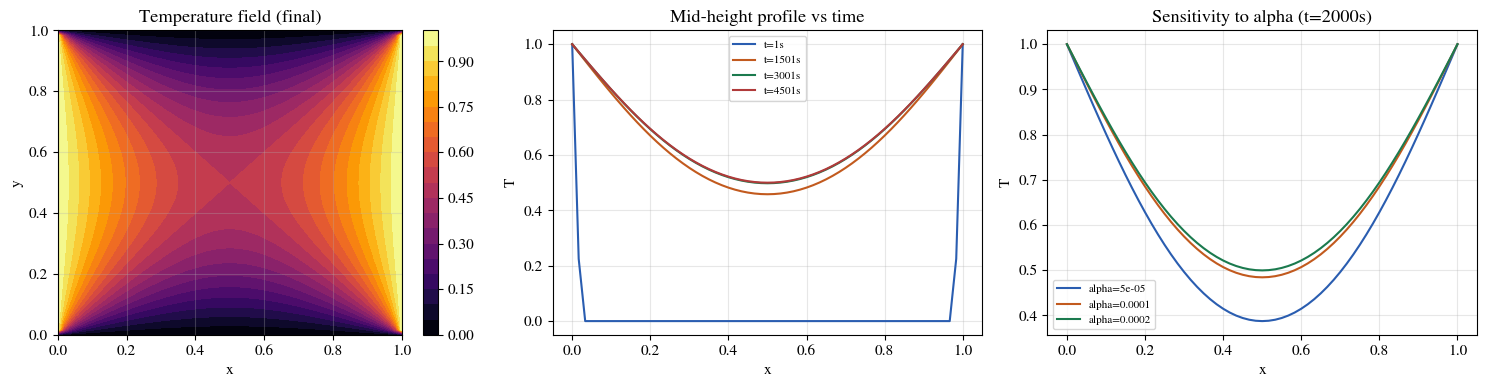

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
im = ax[0].contourf(x, y, T.T, 20, cmap='inferno')
ax[0].set(title='Temperature field (final)', xlabel='x', ylabel='y'); fig.colorbar(im, ax=ax[0])
for f, tt in zip(frames[::max(1,len(frames)//4)], times[::max(1,len(times)//4)]):
    ax[1].plot(x, f[:, p.ny//2], label=f't={tt:.0f}s')
ax[1].set(title='Mid-height profile vs time', xlabel='x', ylabel='T'); ax[1].legend(fontsize=8)
for a in [5e-5, 1e-4, 2e-4]:
    pp = heat.HeatProblem(nx=61, ny=61, alpha=a, T_left=1.0, T_right=1.0, T_top=0.0, T_bottom=0.0)
    _, _, Tf = heat.solve(pp, t_end=2000.0)
    ax[2].plot(x, Tf[:, pp.ny//2], label=f'alpha={a:g}')
ax[2].set(title='Sensitivity to alpha (t=2000s)', xlabel='x', ylabel='T'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

Read the three panels together. **Left:** the steady field is hot ($T\approx1$) along the left and right Dirichlet walls and cold ($T\approx0$) along top and bottom, with a saddle at the centre where the hot and cold influences balance at $T\approx0.5$. **Middle:** at $t=1\,$s (blue) the interior is still flat at $0$ with the boundary values only spiking at the very edges — heat has not penetrated; by $t\approx1500\,$s the profile has filled into a symmetric U dipping to $\approx0.5$ at mid-span, and the $t\approx3000$ and $4500\,$s curves lie on top of it — **steady state reached**. **Right:** at the fixed $t=2000\,$s the largest diffusivity $\alpha=2\times10^{-4}$ (green) has nearly reached the steady U ($\approx0.5$ at centre) while $\alpha=5\times10^{-5}$ (blue) has only reached $\approx0.39$ — confirming $\tau\sim L^2/\alpha$: **halving $\alpha$ roughly doubles the time to equilibrate**.

**Hand-off.** An unknown or wrong source term $\dot q$ / boundary condition is the canonical defect the **corrective source-term approach** (module 20) repairs.

### Save a reference solution

Persist the final field and its grid to `../data/heat_reference.npz` (arrays `x`, `y`, `T`, and the diffusivity `alpha`). This is the ground-truth artifact the data-driven and corrective-source modules later load, so a surrogate is trained against exactly this FTCS solution.

In [5]:
os.makedirs('../data', exist_ok=True)
np.savez('../data/heat_reference.npz', x=x, y=y, T=T, alpha=p.alpha)
print('saved ../data/heat_reference.npz')

saved ../data/heat_reference.npz


Confirms the reference was written to `../data/heat_reference.npz`. It bundles the converged field `T`, the grid `x`, `y`, and `alpha=1e-4` — a self-contained ground truth for the downstream data-driven notebooks.

### Results example — a real circuit board (photo → chips → FTCS)

The same FTCS scheme with a **source term** and **variable diffusivity**. A photo of a PCB is segmented into its four dark chips; each chip is given a higher diffusivity ($\alpha_{\text{chip}}=5\times10^{-5}$ vs board $\alpha_{\text{board}}=10^{-5}\,$m$^2$/s) and a constant heating rate $S_0\in\{55,40,70,30\}$ over its footprint. The board is $10\,$cm square on a $120\times120$ grid with insulated (zero-flux) edges and ambient $T_\infty=300\,$K. A **fan** is modelled as a distributed convective sink $-h(T-T_\infty)$: the field is solved to quasi-steady twice, with the fan off ($h=0$) and on ($h=6$).

4 chips; peak no-fan 436 K, fan 311 K, drop 125 K


heat_circuit saved; assertion passed


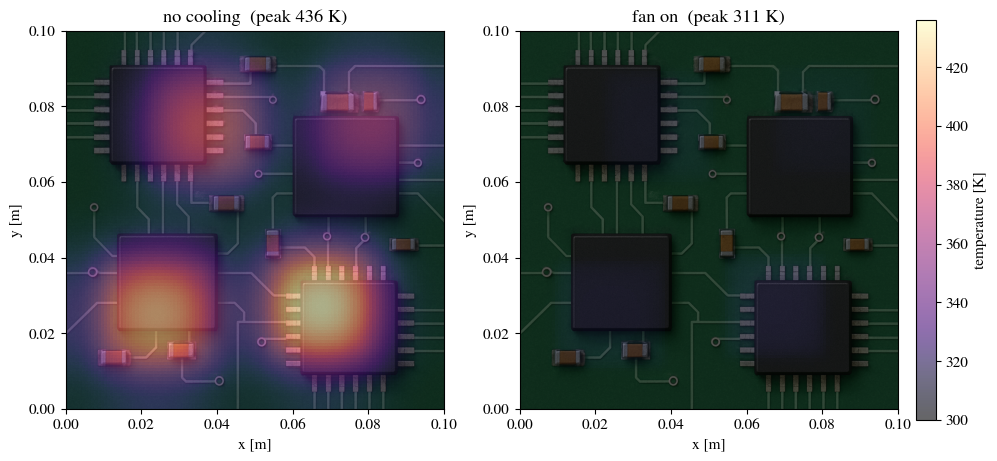

In [6]:
# --- Results example: a real circuit board (photo + segmented chips + FTCS) ---
import matplotlib.pyplot as plt
from PIL import Image
from pyutils import save_dual
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
DATA = os.path.join('..', 'data', 'pcb_circuit.png')

nx = ny = 120
Lx = Ly = 0.10                    # 10 cm square board
dx, dy = Lx/nx, Ly/ny
alpha_board, alpha_chip = 1e-5, 5e-5

img = np.array(Image.open(DATA).convert('RGB'))
try:                              # segment the four dark chips from the photo
    from skimage.color import rgb2hsv
    from skimage.transform import resize
    from scipy.ndimage import label, find_objects
    small = resize(img, (nx, ny), preserve_range=True).astype(np.uint8)
    lab, ncc = label(rgb2hsv(small)[..., 2] < 0.25)
    areas = sorted(((i, int(np.sum(lab == i))) for i in range(1, ncc+1)),
                   key=lambda t: t[1], reverse=True)
    lab, _ = label(np.isin(lab, [i for i, _ in areas[:4]]))
    rects = [(s[0].start, s[0].stop, s[1].start, s[1].stop)
             for s in find_objects(lab) if s is not None]
    assert len(rects) == 4
except Exception:                 # fallback: chip boxes on the 120x120 grid
    rects = [(11, 46, 13, 47), (27, 61, 72, 107), (65, 97, 16, 49), (80, 112, 74, 109)]

# variable diffusivity (chips conduct better) + a constant heat source per chip
alpha = np.full((nx, ny), alpha_board)
S0    = np.zeros((nx, ny))
for k, (x0, x1, y0, y1) in enumerate(rects):
    alpha[x0:x1, y0:y1] = alpha_chip
    S0[x0:x1, y0:y1]    = [55.0, 40.0, 70.0, 30.0][k % 4]

def solve_board(h_fan, t_max=6.0, T_amb=300.0):
    """FTCS to quasi-steady; a 'fan' is a convective sink -h_fan (T - T_amb)."""
    dt = 0.2 * (dx**2 * dy**2) / (2 * alpha_chip * (dx**2 + dy**2))
    T = np.full((nx, ny), T_amb)
    for _ in range(int(t_max / dt)):
        Tn = T; lap = np.zeros_like(T)
        lap[1:-1, 1:-1] = ((Tn[2:, 1:-1] - 2*Tn[1:-1, 1:-1] + Tn[:-2, 1:-1]) / dx**2
                         + (Tn[1:-1, 2:] - 2*Tn[1:-1, 1:-1] + Tn[1:-1, :-2]) / dy**2)
        T = Tn + dt * (alpha * lap + S0 - h_fan * (Tn - T_amb))
        T[0, :] = T[1, :]; T[-1, :] = T[-2, :]; T[:, 0] = T[:, 1]; T[:, -1] = T[:, -2]
    return T

T_nofan = solve_board(0.0)
T_fan   = solve_board(6.0)
peak0, peak1 = float(T_nofan.max()), float(T_fan.max())
print(f'{len(rects)} chips; peak no-fan {peak0:.0f} K, fan {peak1:.0f} K, drop {peak0-peak1:.0f} K')

def plot_circuit():
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 5.2))
    for a, T, ttl in [(ax[0], T_nofan, f'no cooling  (peak {peak0:.0f} K)'),
                      (ax[1], T_fan,   f'fan on  (peak {peak1:.0f} K)')]:
        a.imshow(img, origin='upper', extent=[0, Lx, 0, Ly])
        im = a.imshow(T.T[::-1], cmap='magma', origin='upper', extent=[0, Lx, 0, Ly],
                      alpha=0.6, vmin=300.0, vmax=peak0)
        a.set(title=ttl, xlabel='x [m]', ylabel='y [m]'); a.grid(False)
    fig.colorbar(im, ax=ax, label='temperature [K]', fraction=0.046, pad=0.02)

save_dual(plot_circuit, 'heat_circuit', FIG)
assert (peak0 - peak1) > 80
print('heat_circuit saved; assertion passed')

The print reports **four chips, peak 436 K with no cooling, 311 K with the fan — a 125 K drop** (the `assert (peak0 - peak1) > 80` passes). In the left panel the two lower chips run hottest (the bottom-right, strongest source $S_0=70$, glows near $430\,$K) and their heat visibly **bleeds into the board and toward neighbours** rather than staying under the footprint — crowded chips run hotter. In the right panel the convective sink pulls the whole board back to near ambient ($\approx300\,$K), the chips only faintly warm: a distributed fan is the cheapest lever on the hot-spot, and its strength $h$ is exactly the coefficient a data-driven correction would later calibrate.